In [7]:
%pip install matplotlib pandas geopandas

  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-13.0.0-cp312-cp312-macosx_11_0_arm64.whl (4.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
print('helorh')

helorh


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import geopandas as gpd

In [5]:
gdf_ciclovias = gpd.read_file("ciclovias existentes.geojson")

In [6]:
gdf_ciclovias.head()

,id,@id,access,alt_name,bicycle,bridge,bridge:name,bus:lanes,busway:left,busway:right,...,tunnel,turn:lanes,turn:lanes:conditional,turn:psv:lanes,vehicle:lanes,vehicle:lanes:conditional,wheelchair,width,wikipedia,geometry
0,way/5137075,way/5137075,NaN,Ponte da Travessia Régis Bittencourt Quarto,yes,yes,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.27921 -29.99426, -51.27319 -29..."
1,way/26786712,way/26786712,NaN,NaN,designated,NaN,NaN,NaN,lane,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15165 -30.06563, -51.15145 -30..."
2,way/26786732,way/26786732,NaN,Avenida Antônio Carvalho,designated,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15031 -30.06621, -51.15063 -30..."
3,way/26786733,way/26786733,NaN,NaN,use_sidepath,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15121 -30.06519, -51.15119 -30..."
4,way/26983698,way/26983698,NaN,NaN,use_sidepath,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.19444 -30.0391, -51.19438 -30...."


In [7]:

from matplotlib.lines import Line2D

# Carregando os arquivos GeoJSON
print("Carregando os dados geoespaciais de Porto Alegre...")
gdf_malha_viaria = gpd.read_file('malha viaria.geojson')
gdf_ciclovias = gpd.read_file('ciclovias existentes.geojson')
gdf_pontos = gpd.read_file('pontos interesse.geojson')
print("Dados carregados com sucesso!")

Carregando os dados geoespaciais de Porto Alegre...
Dados carregados com sucesso!


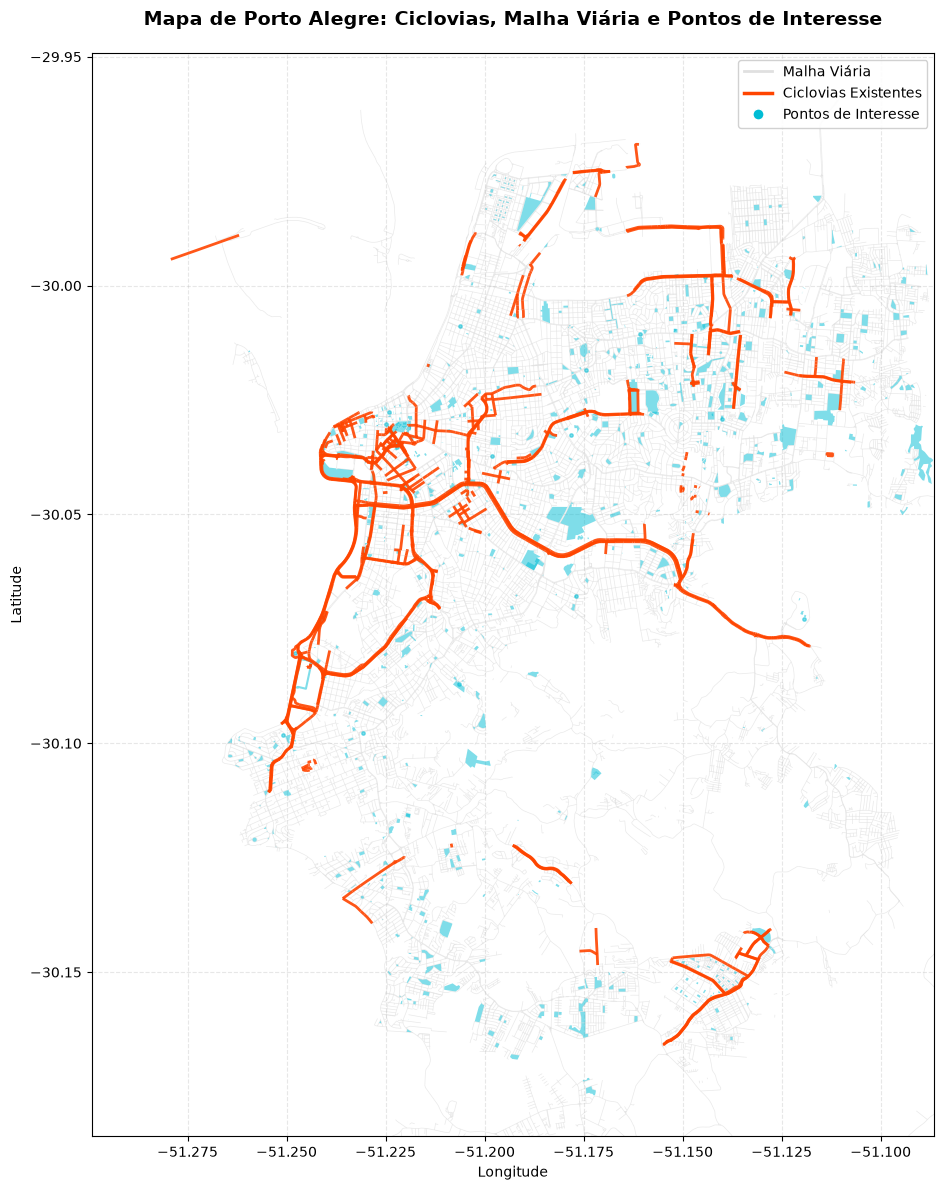

In [8]:
# Criando a visualização integrada com zoom ajustado
fig, ax = plt.subplots(figsize=(12, 12))

# 1. Malha Viária (Fundo)
gdf_malha_viaria.plot(ax=ax, color='#E0E0E0', linewidth=0.5, alpha=0.7, label='Malha Viária', zorder=1)

# 2. Pontos de Interesse
gdf_pontos.plot(ax=ax, color='#00BCD4', markersize=6, alpha=0.5, label='Pontos de Interesse', zorder=2)

# 3. Ciclovias Existentes (Destaque)
gdf_ciclovias.plot(ax=ax, color='#FF4500', linewidth=2.0, alpha=0.9, label='Ciclovias', zorder=3)

# Obtendo os limites (bounding box) da rede de ciclovias para focar o mapa em Porto Alegre
minx, miny, maxx, maxy = gdf_ciclovias.total_bounds
ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)

# Customizações estéticas
plt.title('Mapa de Porto Alegre: Ciclovias, Malha Viária e Pontos de Interesse', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

# Legenda esteticamente limpa
legend_elements = [
    Line2D([0], [0], color='#E0E0E0', lw=2, label='Malha Viária'),
    Line2D([0], [0], color='#FF4500', lw=2.5, label='Ciclovias Existentes'),
    Line2D([0], [0], marker='o', color='w', label='Pontos de Interesse', markerfacecolor='#00BCD4', markersize=8)
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

In [9]:
# Verificando e garantindo que todos os GeoDataFrames usem o mesmo CRS (WGS84)
target_crs = 'EPSG:4326'


In [10]:
# Carregando as duas novas fontes de dados
gdf_onibus = gpd.read_file('bus stop.geojson')
gdf_conexoes = gpd.read_file('conexoes.geojson')

# Garantindo a compatibilidade de projeção (CRS) para WGS84
gdf_onibus = gdf_onibus.to_crs(target_crs)
gdf_conexoes = gdf_conexoes.to_crs(target_crs)

print(f"Quantidade de paradas de ônibus carregadas: {len(gdf_onibus)}")
print(f"Quantidade de conexões intermunicipais carregadas: {len(gdf_conexoes)}")

Quantidade de paradas de ônibus carregadas: 1543
Quantidade de conexões intermunicipais carregadas: 385


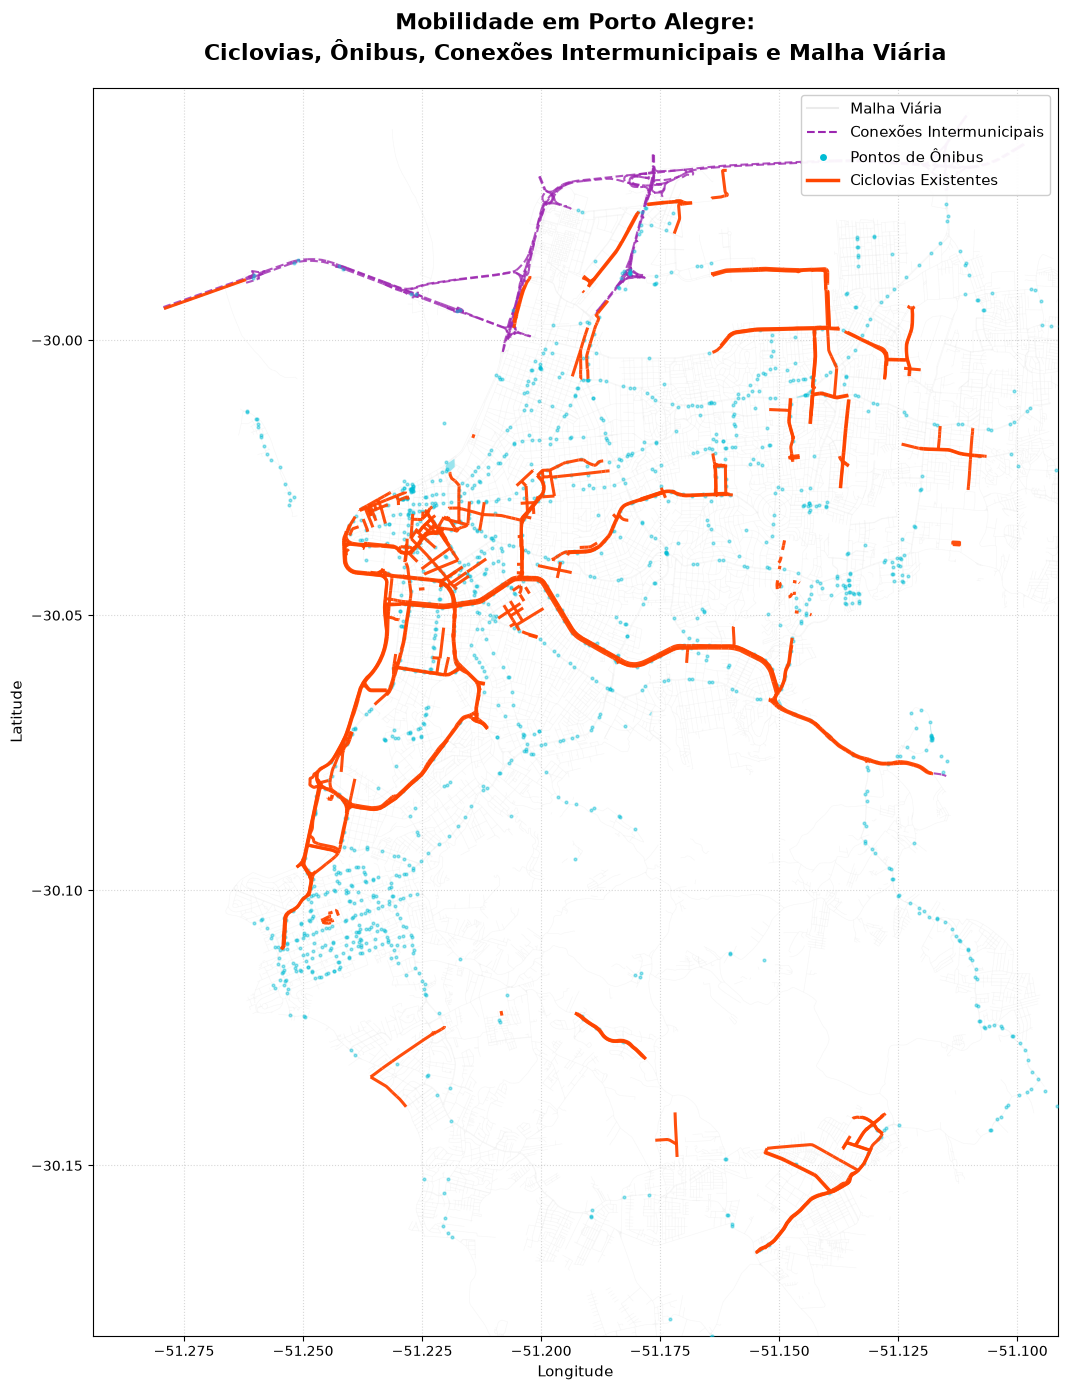

In [11]:
# Criando a visualização integrada com todas as camadas
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Malha Viária (Fundo - cinza muito claro para não poluir)
gdf_malha_viaria.plot(ax=ax, color='#EBEBEB', linewidth=0.4, alpha=0.5, label='Malha Viária', zorder=1)

# 2. Conexões Intermunicipais (Linhas roxas pontilhadas para diferenciar das ciclovias)
gdf_conexoes.plot(ax=ax, color='#9C27B0', linewidth=1.5, linestyle='--', alpha=0.8, label='Conexões Intermunicipais', zorder=2)

# 3. Pontos de Ônibus (Marcadores azuis pequenos e semi-transparentes devido à densidade)
gdf_onibus.plot(ax=ax, color='#00BCD4', markersize=4, alpha=0.4, label='Pontos de Ônibus', zorder=3)

# 4. Ciclovias Existentes (Destaque principal em vermelho/coral)
gdf_ciclovias.plot(ax=ax, color='#FF4500', linewidth=2.2, alpha=0.95, label='Ciclovias Existentes', zorder=4)

# Mantendo o zoom focado na extensão das ciclovias de Porto Alegre
minx, miny, maxx, maxy = gdf_ciclovias.total_bounds
ax.set_xlim(minx - 0.015, maxx + 0.015)
ax.set_ylim(miny - 0.015, maxy + 0.015)

# Detalhes visuais e títulos
plt.title('Mobilidade em Porto Alegre:\nCiclovias, Ônibus, Conexões Intermunicipais e Malha Viária', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Longitude', fontsize=11)
plt.ylabel('Latitude', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)

# Legenda esteticamente limpa e informativa
legend_elements = [
    Line2D([0], [0], color='#EBEBEB', lw=1.5, label='Malha Viária'),
    Line2D([0], [0], color='#9C27B0', lw=1.5, linestyle='--', label='Conexões Intermunicipais'),
    Line2D([0], [0], marker='o', color='w', label='Pontos de Ônibus', markerfacecolor='#00BCD4', markersize=6),
    Line2D([0], [0], color='#FF4500', lw=2.5, label='Ciclovias Existentes')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=11)

plt.tight_layout()
plt.show()

In [12]:
gdf_ciclovias.head()

,id,@id,access,alt_name,bicycle,bridge,bridge:name,bus:lanes,busway:left,busway:right,...,tunnel,turn:lanes,turn:lanes:conditional,turn:psv:lanes,vehicle:lanes,vehicle:lanes:conditional,wheelchair,width,wikipedia,geometry
0,way/5137075,way/5137075,NaN,Ponte da Travessia Régis Bittencourt Quarto,yes,yes,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.27921 -29.99426, -51.27319 -29..."
1,way/26786712,way/26786712,NaN,NaN,designated,NaN,NaN,NaN,lane,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15165 -30.06563, -51.15145 -30..."
2,way/26786732,way/26786732,NaN,Avenida Antônio Carvalho,designated,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15031 -30.06621, -51.15063 -30..."
3,way/26786733,way/26786733,NaN,NaN,use_sidepath,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.15121 -30.06519, -51.15119 -30..."
4,way/26983698,way/26983698,NaN,NaN,use_sidepath,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"LINESTRING (-51.19444 -30.0391, -51.19438 -30...."


In [13]:
coord_ciclovias=gdf_ciclovias['geometry']
id_ciclovia= gdf_ciclovias['id']

In [35]:
coord_ciclovias.shape

(2084,)

In [36]:
id_ciclovia.shape

(2084,)

In [14]:
coord_malha_viaria = gdf_malha_viaria['geometry']
id_malha = gdf_malha_viaria['id']
bicycle_malha = gdf_malha_viaria['bicycle']

In [37]:
coord_malha_viaria.shape

(17782,)

In [38]:
id_malha.shape

(17782,)

In [39]:
bicycle_malha.shape

(17782,)

In [15]:
coord_onibus = gdf_onibus['geometry']

In [120]:
coord_pontos = gdf_pontos['geometry']
id_pontos = gdf_pontos['id']

(2084,)


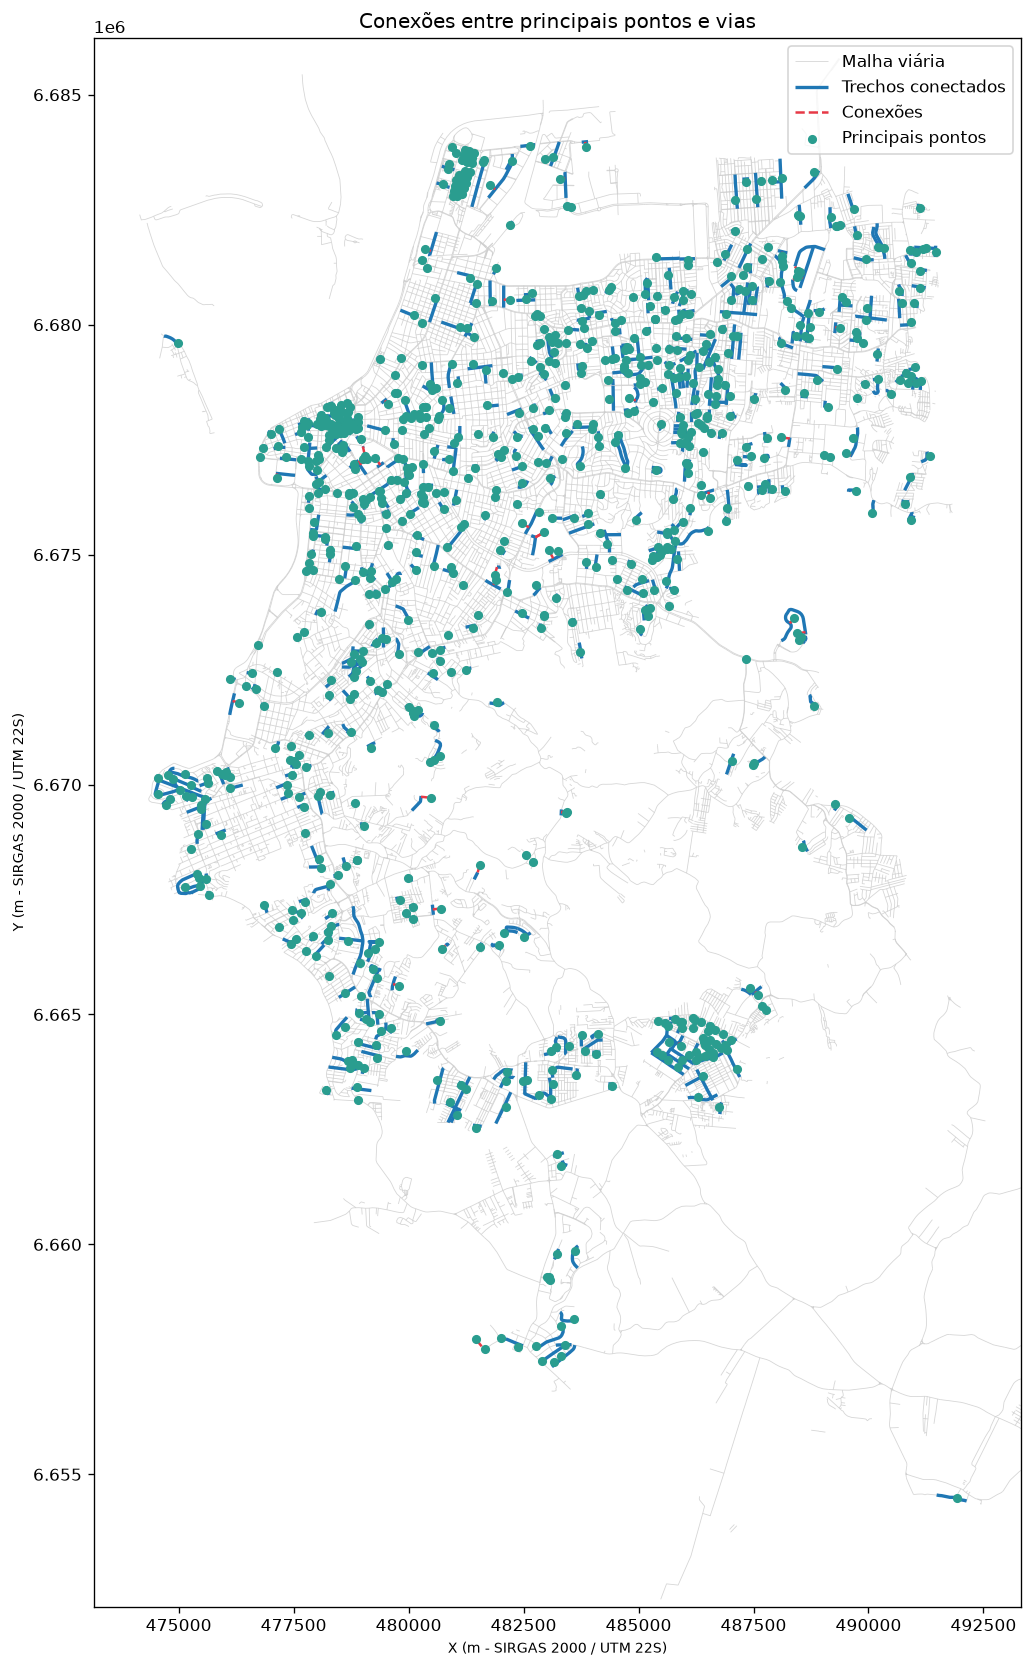

In [33]:
import json

# Usa as variáveis já criadas no notebook (em metros EPSG:31982 para plotar)
malha_plot = gdf_malha_viaria.to_crs(31982)
pts_plot = gdf_pontos.to_crs(31982).copy()
pts_plot["geometry"] = pts_plot.geometry.centroid

if "conn_plot" in globals() and len(conn_plot) > 0:
    conex_plot = conn_plot
elif "gdf_conexoes_geojson" in globals() and len(gdf_conexoes_geojson) > 0:
    conex_plot = gpd.GeoDataFrame.from_features(
        json.loads(gdf_conexoes_geojson.to_json()), crs=4326
    ).to_crs(31982)
else:
    conex_plot = None

fig, ax = plt.subplots(figsize=(14, 14), dpi=120)

# 1. Fundo: malha viária
malha_plot.plot(ax=ax, color="#cccccc", linewidth=0.5, alpha=0.8, label="Malha viária")

# 2. Conexões e trechos conectados
if conex_plot is not None and len(conex_plot) > 0:
    col_idx = "rod_idx" if "rod_idx" in conex_plot.columns else ("index_right" if "index_right" in conex_plot.columns else None)
    if col_idx is not None:
        trechos_conectados = malha_plot[malha_plot.index.isin(conex_plot[col_idx])]
        if len(trechos_conectados) > 0:
            trechos_conectados.plot(ax=ax, color="#1f77b4", linewidth=2.0, label="Trechos conectados")

    conex_plot.plot(ax=ax, color="#e63946", linewidth=1.5, linestyle="--", zorder=3, label="Conexões")

# 3. Pontos principais
pts_plot.plot(ax=ax, color="#2a9d8f", markersize=20, zorder=4, label="Principais pontos")

# 4. Garante limites válidos a partir dos pontos/conexões (evita zoom extremo em outlier)
xmin, ymin, xmax, ymax = pts_plot.total_bounds
pad_x = (xmax - xmin) * 0.08
pad_y = (ymax - ymin) * 0.08
ax.set_xlim(xmin - pad_x, xmax + pad_x)
ax.set_ylim(ymin - pad_y, ymax + pad_y)

ax.set_title("Conexões entre principais pontos e vias")
ax.set_xlabel("X (m - SIRGAS 2000 / UTM 22S)")
ax.set_ylabel("Y (m - SIRGAS 2000 / UTM 22S)")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

In [19]:
import json

# Usa o GeoDataFrame de conexões já gerado no notebook (prioriza gdf_conexoes_geojson, senão conn_plot ou gdf_conexoes)
if "gdf_conexoes_geojson" in globals() and len(gdf_conexoes_geojson) > 0:
    base_4326 = gdf_conexoes_geojson.to_crs(epsg=4326).copy()
elif "conn_plot" in globals() and len(conn_plot) > 0:
    base_4326 = conn_plot.to_crs(epsg=4326).copy()
elif "gdf_conexoes" in globals() and len(gdf_conexoes) > 0:
    base_4326 = gdf_conexoes.to_crs(epsg=4326).copy()
else:
    raise ValueError("Nenhum GeoDataFrame de conexões encontrado no notebook.")

base_m = base_4326.to_crs(epsg=31982).copy()

registros_coords = []

for idx, (row_4326, row_m) in enumerate(zip(base_4326.itertuples(), base_m.itertuples())):
    geom_4326 = row_4326.geometry
    geom_m = row_m.geometry

    if geom_4326 is None or geom_4326.is_empty:
        continue

    # Garante que pegamos uma LineString (caso venha MultiLineString, pega a primeira parte)
    linha_4326 = list(geom_4326.geoms)[0] if geom_4326.geom_type == "MultiLineString" else geom_4326
    linha_m = list(geom_m.geoms)[0] if geom_m.geom_type == "MultiLineString" else geom_m

    coords_4326 = list(linha_4326.coords)  # [(lon, lat), ...]
    coords_m = list(linha_m.coords)        # [(x, y), ...]

    lon_origem, lat_origem = coords_4326[0][0], coords_4326[0][1]
    lon_destino, lat_destino = coords_4326[-1][0], coords_4326[-1][1]

    x_origem, y_origem = coords_m[0][0], coords_m[0][1]
    x_destino, y_destino = coords_m[-1][0], coords_m[-1][1]

    item = {
        "conexao_id": idx,
        "lon_origem": round(lon_origem, 6),
        "lat_origem": round(lat_origem, 6),
        "lon_destino": round(lon_destino, 6),
        "lat_destino": round(lat_destino, 6),
        "x_origem_m": round(x_origem, 2),
        "y_origem_m": round(y_origem, 2),
        "x_destino_m": round(x_destino, 2),
        "y_destino_m": round(y_destino, 2),
        "coords_lon_lat": [[round(c[0], 6), round(c[1], 6)] for c in coords_4326],
        "coords_xy_m": [[round(c[0], 2), round(c[1], 2)] for c in coords_m],
    }

    # Mantém colunas úteis se existirem (como distância ou índice da via)
    for col in ["dist_m", "distancia_m", "rod_idx", "index_right", "ponto_id"]:
        if hasattr(row_4326, col):
            item[col] = getattr(row_4326, col)

    registros_coords.append(item)

df_coords_conexoes = pd.DataFrame(registros_coords)
print(f"Total de conexões com coordenadas extraídas: {len(df_coords_conexoes)}")
display(df_coords_conexoes.head(10))

# Opcional: estrutura tipo dicionário/JSON com as coordenadas de cada conexão
coords_geojson_dict = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {k: v for k, v in rec.items() if k not in ["coords_lon_lat", "coords_xy_m"]},
            "geometry": {
                "type": "LineString",
                "coordinates": rec["coords_lon_lat"],
            },
        }
        for rec in registros_coords
    ],
}
coords_json_str = json.dumps(coords_geojson_dict, ensure_ascii=False, indent=2)

Total de conexões com coordenadas extraídas: 928


,conexao_id,lon_origem,lat_origem,lon_destino,lat_destino,x_origem_m,y_origem_m,x_destino_m,y_destino_m,coords_lon_lat,coords_xy_m,dist_m,index_right
0,0,-51.120497,-30.068522,-51.121507,-30.069510,488386.32,6673615.69,488289.10,6673506.11,"[[-51.120497, -30.068522], [-51.121507, -30.06...","[[488386.32, 6673615.69], [488289.1, 6673506.11]]",146.479870,3686
1,1,-51.207310,-30.040255,-51.208068,-30.040283,480013.49,6676735.95,479940.44,6676732.74,"[[-51.20731, -30.040255], [-51.208068, -30.040...","[[480013.49, 6676735.95], [479940.44, 6676732....",73.119395,3476
2,2,-51.176836,-30.051546,-51.178862,-30.052557,482953.35,6675489.70,482758.29,6675377.42,"[[-51.176836, -30.051546], [-51.178862, -30.05...","[[482953.35, 6675489.7], [482758.29, 6675377.42]]",225.078258,490
3,3,-51.176836,-30.051546,-51.178862,-30.052557,482953.35,6675489.70,482758.29,6675377.42,"[[-51.176836, -30.051546], [-51.178862, -30.05...","[[482953.35, 6675489.7], [482758.29, 6675377.42]]",225.078258,12199
4,4,-51.187298,-30.036207,-51.186866,-30.036554,481942.05,6677187.83,481983.80,6677149.45,"[[-51.187298, -30.036207], [-51.186866, -30.03...","[[481942.05, 6677187.83], [481983.8, 6677149.45]]",56.712532,15110
5,5,-51.225882,-30.129875,-51.226141,-30.129654,478242.57,6666801.74,478217.64,6666826.18,"[[-51.225882, -30.129875], [-51.226141, -30.12...","[[478242.57, 6666801.74], [478217.64, 6666826....",34.914753,2835
6,6,-51.264227,-30.102788,-51.264141,-30.103112,474542.21,6669795.33,474550.57,6669759.53,"[[-51.264227, -30.102788], [-51.264141, -30.10...","[[474542.21, 6669795.33], [474550.57, 6669759....",36.765252,5248
7,7,-51.259074,-30.102111,-51.258910,-30.101733,475038.52,6669871.49,475054.22,6669913.45,"[[-51.259074, -30.102111], [-51.25891, -30.101...","[[475038.52, 6669871.49], [475054.22, 6669913....",44.803317,5246
8,8,-51.256527,-30.103421,-51.256867,-30.103185,475284.18,6669726.92,475251.38,6669752.98,"[[-51.256527, -30.103421], [-51.256867, -30.10...","[[475284.18, 6669726.92], [475251.38, 6669752....",41.889656,2871
9,9,-51.262430,-30.104985,-51.262356,-30.104859,474715.88,6669552.32,474723.01,6669566.26,"[[-51.26243, -30.104985], [-51.262356, -30.104...","[[474715.88, 6669552.32], [474723.01, 6669566....",15.658562,2867


In [20]:
df_coords_conexoes[["conexao_id", "lon_origem", "lat_origem", "lon_destino", "lat_destino"]]

,conexao_id,lon_origem,lat_origem,lon_destino,lat_destino
0,0,-51.120497,-30.068522,-51.121507,-30.069510
1,1,-51.207310,-30.040255,-51.208068,-30.040283
2,2,-51.176836,-30.051546,-51.178862,-30.052557
3,3,-51.176836,-30.051546,-51.178862,-30.052557
4,4,-51.187298,-30.036207,-51.186866,-30.036554
...,...,...,...,...,...
923,923,-51.206137,-30.008818,-51.206235,-30.009025
924,924,-51.140135,-30.029215,-51.140206,-30.029352
925,925,-51.177007,-30.067920,-51.177183,-30.067820
926,926,-51.224021,-30.027598,-51.223969,-30.027579


In [25]:
df_coords_conexoes

,conexao_id,lon_origem,lat_origem,lon_destino,lat_destino,x_origem_m,y_origem_m,x_destino_m,y_destino_m,coords_lon_lat,coords_xy_m,dist_m,index_right
0,0,-51.120497,-30.068522,-51.121507,-30.069510,488386.32,6673615.69,488289.10,6673506.11,"[[-51.120497, -30.068522], [-51.121507, -30.06...","[[488386.32, 6673615.69], [488289.1, 6673506.11]]",146.479870,3686
1,1,-51.207310,-30.040255,-51.208068,-30.040283,480013.49,6676735.95,479940.44,6676732.74,"[[-51.20731, -30.040255], [-51.208068, -30.040...","[[480013.49, 6676735.95], [479940.44, 6676732....",73.119395,3476
2,2,-51.176836,-30.051546,-51.178862,-30.052557,482953.35,6675489.70,482758.29,6675377.42,"[[-51.176836, -30.051546], [-51.178862, -30.05...","[[482953.35, 6675489.7], [482758.29, 6675377.42]]",225.078258,490
3,3,-51.176836,-30.051546,-51.178862,-30.052557,482953.35,6675489.70,482758.29,6675377.42,"[[-51.176836, -30.051546], [-51.178862, -30.05...","[[482953.35, 6675489.7], [482758.29, 6675377.42]]",225.078258,12199
4,4,-51.187298,-30.036207,-51.186866,-30.036554,481942.05,6677187.83,481983.80,6677149.45,"[[-51.187298, -30.036207], [-51.186866, -30.03...","[[481942.05, 6677187.83], [481983.8, 6677149.45]]",56.712532,15110
...,...,...,...,...,...,...,...,...,...,...,...,...,...
923,923,-51.206137,-30.008818,-51.206235,-30.009025,480120.27,6680219.62,480110.93,6680196.75,"[[-51.206137, -30.008818], [-51.206235, -30.00...","[[480120.27, 6680219.62], [480110.93, 6680196....",24.711236,14925
924,924,-51.140135,-30.029215,-51.140206,-30.029352,486488.28,6677969.08,486481.40,6677953.94,"[[-51.140135, -30.029215], [-51.140206, -30.02...","[[486488.28, 6677969.08], [486481.4, 6677953.94]]",16.627514,2147
925,925,-51.177007,-30.067920,-51.177183,-30.067820,482939.71,6673675.27,482922.75,6673686.36,"[[-51.177007, -30.06792], [-51.177183, -30.067...","[[482939.71, 6673675.27], [482922.75, 6673686....",20.261693,6717
926,926,-51.224021,-30.027598,-51.223969,-30.027579,478399.61,6678135.47,478404.68,6678137.59,"[[-51.224021, -30.027598], [-51.223969, -30.02...","[[478399.61, 6678135.47], [478404.68, 6678137....",5.497319,98


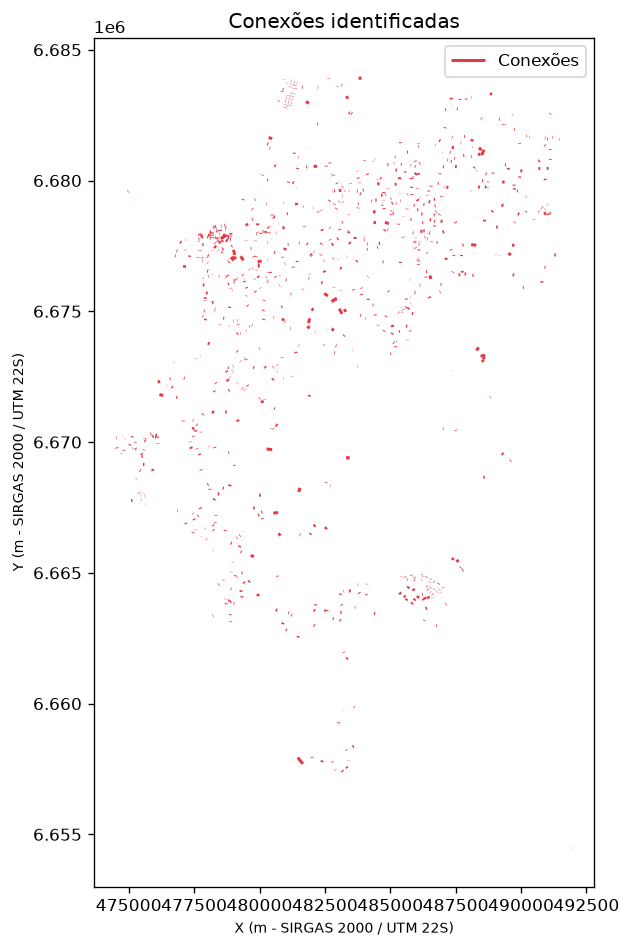

In [21]:
import json

# Seleciona o objeto de conexões disponível no notebook
if "gdf_conexoes_geojson" in globals() and len(gdf_conexoes_geojson) > 0:
    conex_plot = gpd.GeoDataFrame.from_features(
        json.loads(gdf_conexoes_geojson.to_json()), crs=4326
    ).to_crs(31982)
elif "conn_plot" in globals() and len(conn_plot) > 0:
    conex_plot = conn_plot.to_crs(31982)
elif "gdf_conexoes" in globals() and len(gdf_conexoes) > 0:
    conex_plot = gdf_conexoes.to_crs(31982)
else:
    raise ValueError("Nenhuma conexão encontrada no notebook.")

fig, ax = plt.subplots(figsize=(11, 8), dpi=120)

conex_plot.plot(ax=ax, color="#e63946", linewidth=1.8, label="Conexões")

xmin, ymin, xmax, ymax = conex_plot.total_bounds
pad_x = max((xmax - xmin) * 0.05, 200)
pad_y = max((ymax - ymin) * 0.05, 200)
ax.set_xlim(xmin - pad_x, xmax + pad_x)
ax.set_ylim(ymin - pad_y, ymax + pad_y)

ax.set_title("Conexões identificadas")
ax.set_xlabel("X (m - SIRGAS 2000 / UTM 22S)")
ax.set_ylabel("Y (m - SIRGAS 2000 / UTM 22S)")
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
from shapely.geometry import LineString

# Garante que 'coords' tenha pares (lon, lat) e monta a coluna geometry
df_coords["geometry"] = df_coords["coords"].apply(lambda c: LineString(c))

# Converte de volta para GeoDataFrame em EPSG:4326
gdf_coords = gpd.GeoDataFrame(df_coords, geometry="geometry", crs="EPSG:4326")

gdf_coords.head()

,origem_lon_lat,destino_lon_lat,coords,geometry
0,"(-51.120497, -30.068522)","(-51.121507, -30.06951)","[(-51.120497, -30.068522), (-51.121507, -30.06...","LINESTRING (-51.1205 -30.06852, -51.12151 -30...."
1,"(-51.20731, -30.040255)","(-51.208068, -30.040283)","[(-51.20731, -30.040255), (-51.208068, -30.040...","LINESTRING (-51.20731 -30.04026, -51.20807 -30..."
2,"(-51.176836, -30.051546)","(-51.178862, -30.052557)","[(-51.176836, -30.051546), (-51.178862, -30.05...","LINESTRING (-51.17684 -30.05155, -51.17886 -30..."
3,"(-51.176836, -30.051546)","(-51.178862, -30.052557)","[(-51.176836, -30.051546), (-51.178862, -30.05...","LINESTRING (-51.17684 -30.05155, -51.17886 -30..."
4,"(-51.187298, -30.036207)","(-51.186866, -30.036554)","[(-51.187298, -30.036207), (-51.186866, -30.03...","LINESTRING (-51.1873 -30.03621, -51.18687 -30...."


In [27]:
coordenadas_conexoes=df_coords['geometry']

In [30]:
dist=df_coords_conexoes['dist_m']

In [40]:
coordenadas_conexoes

0      LINESTRING (-51.12049716078167 -30.06852210155...
1      LINESTRING (-51.20730990017646 -30.04025505000...
2      LINESTRING (-51.17683631546155 -30.05154629011...
3      LINESTRING (-51.17683631546155 -30.05154629011...
4      LINESTRING (-51.187298405938606 -30.0362069945...
                             ...                        
923    LINESTRING (-51.2061373 -30.00881829999999, -5...
924    LINESTRING (-51.1401348 -30.029215299999997, -...
925    LINESTRING (-51.17700700000001 -30.0679204, -5...
926    LINESTRING (-51.2240214 -30.027597599999993, -...
927    LINESTRING (-51.2248978 -30.030163099999996, -...
Name: geometry, Length: 928, dtype: object

In [42]:
dist

0      146.479870
1       73.119395
2      225.078258
3      225.078258
4       56.712532
          ...    
923     24.711236
924     16.627514
925     20.261693
926      5.497319
927     15.383881
Name: dist_m, Length: 928, dtype: float64

In [45]:
import pandas as pd #cria dataframe com as conexoes e suas extensoes em m

dados_conexoes_possiveis = pd.DataFrame({
    'coordenadas_conect': coordenadas_conexoes,
    'extensao (m)': dist
})


In [46]:
dados_conexoes_possiveis

,coordenadas_conect,extensao (m)
0,LINESTRING (-51.12049716078167 -30.06852210155...,146.479870
1,LINESTRING (-51.20730990017646 -30.04025505000...,73.119395
2,LINESTRING (-51.17683631546155 -30.05154629011...,225.078258
3,LINESTRING (-51.17683631546155 -30.05154629011...,225.078258
4,LINESTRING (-51.187298405938606 -30.0362069945...,56.712532
...,...,...
923,"LINESTRING (-51.2061373 -30.00881829999999, -5...",24.711236
924,"LINESTRING (-51.1401348 -30.029215299999997, -...",16.627514
925,"LINESTRING (-51.17700700000001 -30.0679204, -5...",20.261693
926,"LINESTRING (-51.2240214 -30.027597599999993, -...",5.497319


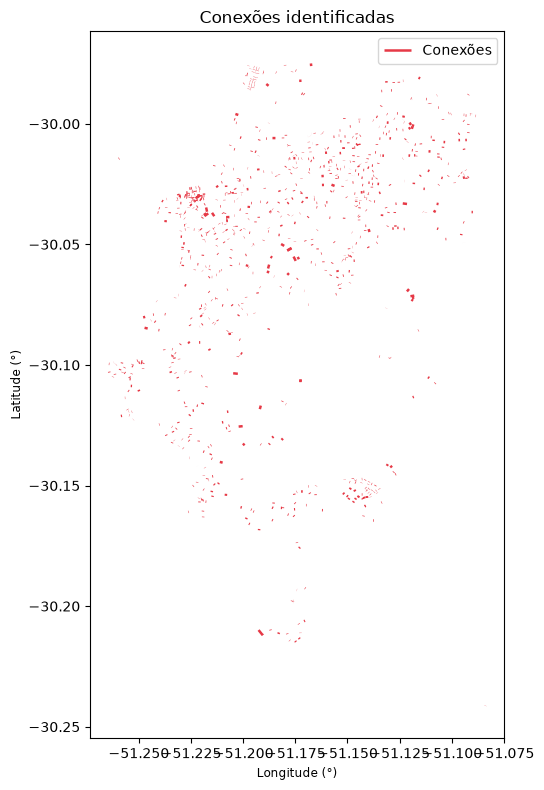

In [23]:
fig, ax = plt.subplots(figsize=(11, 8))

gdf_conn_4326.plot(ax=ax, color="#e63946", linewidth=1.8, label="Conexões")

ax.set_title("Conexões identificadas")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.legend()
plt.tight_layout()
plt.show()